In [20]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
import pyslha
import glob,os
from typing import List, Dict, Tuple

import warnings
warnings.filterwarnings("ignore", message="numpy.dtype size changed")
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.8)
cm = plt.colormaps['RdYlBu']

    

In [21]:
def getXSectionFromSummary(summaryFile : str) -> Tuple:
    """
    Get the cross section from the summary file.
    """
    with open(summaryFile, 'r') as f:
        lines = f.readlines()
        for line in lines:
            if "Total cross section" in line:
                xsecStr = line.split(':')[1].strip()
                xsec,xsecErr = xsecStr.split('+-',1)
                xsecErr = xsecErr.split()[0]
                return (float(xsec), float(xsecErr))
    return (None,None)

def getModelParamsFromBanner(bannerFile : str) -> Dict:
    """
    Get the model parameters from the banner file.
    """
    with open(bannerFile, 'r') as f:
        data= f.read()
    slhaBlock = data.split('<slha>')[1].split('</slha>')[0]
    slha = pyslha.readSLHA(slhaBlock)

    modelInfo = {'masses' : slha.blocks['MASS'], 'parameters' : slha.blocks['FRBLOCK']}
    return modelInfo

## Get Cross-Sections and Parameters

In [ ]:
folderDict = {'Quark-Philic Scalar Mediator' : '../pp2ysu_NLO_xsections/Events',
              'Lepto-Philic Scalar Mediator' : '../pp2yse_NLO_xsections/Events',
            #   'Quark-Philic Fermionic Mediator' : '../pp2yfu_NLO_xsections/Events',
            #   'Lepto-Philic Fermionic Mediator' : '../pp2yfe_NLO_xsections_Leptoic/Events'
              }
parsDict = {}
for label,folder in folderDict.items():
    parsDict[label] = []
    for folder in glob.glob(folder + '/run*'):
        bannerFiles = list(glob.glob(os.path.join(folder, '*banner.txt')))
        if len(bannerFiles) != 1:
            print('Error: found %d banner files in %s' % (len(bannerFiles), folder))
            continue
        bannerFile = bannerFiles[0]
        summaryFile = os.path.join(folder, 'summary.txt')
        if not os.path.isfile(summaryFile):
            print('Error: summary file not found in %s' % folder)
            continue
        xsec_pb = getXSectionFromSummary(summaryFile)
        modelPars = getModelParamsFromBanner(bannerFile)
        modelPars.update({'xsec_pb' : xsec_pb[0], 'xsec_err_pb' : xsec_pb[1]})
        parsDict[label].append(modelPars)

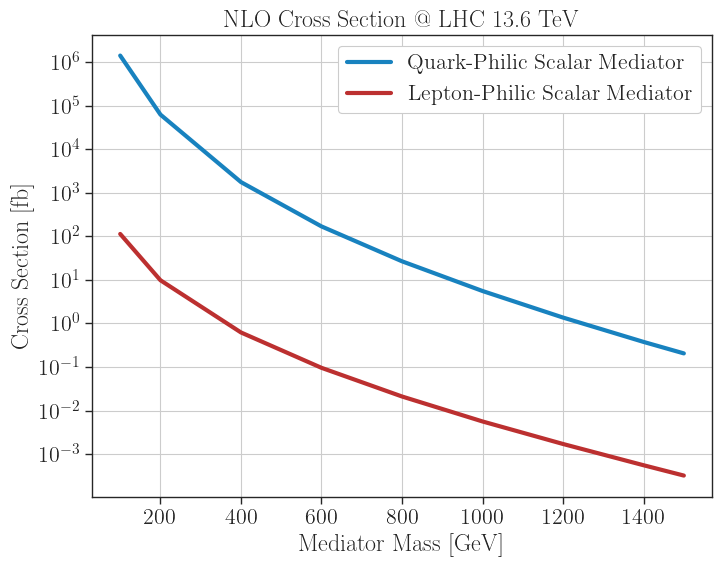

In [ ]:
modelMasses = {'Quark-Philic Scalar Mediator' : 5910002,
              'Lepto-Philic Scalar Mediator' : 5920011,
              'Quark-Philic Fermionic Mediator' : 5910002,
              'Lepto-Philic Fermionic Mediator' : 5920011}

colors = {'Quark-Philic Scalar Mediator' : "#1882BF",
          'Lepto-Philic Scalar Mediator' : "#BC3030",
          'Quark-Philic Fermionic Mediator' : "#1882BF",
          'Lepto-Philic Fermionic Mediator' : "#BC3030"}
fig = plt.figure(figsize=(8,6))
for label, parList in parsDict.items():
    if 'scalar' in label.lower():
        ls = '-'
    else:
        ls = '--'
    massList = [mInfo['masses'][modelMasses[label]] for mInfo in parList]
    xsec = [mInfo['xsec_pb']*1e3 for mInfo in parList]
    pts = np.array(sorted(zip(massList, xsec), key=lambda x: x[0]))
    plt.plot(pts[:, 0], pts[:, 1], label=label,linewidth=3,linestyle=ls,color=colors[label])
plt.legend(framealpha=1.0)
plt.xlabel('Mediator Mass [GeV]')
plt.ylabel('Cross Section [fb]')
plt.yscale('log')
plt.title('NLO Cross Section @ LHC 13.6 TeV')
plt.yticks(np.logspace(-3, 6, 10))
plt.grid()
plt.show()